# Credict Card Fraud Detection

The dataset contains transactions made by credit cards in September 2013 by European cardholders.
This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions. we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. We will look into the data fix the unbalencies of the target labels and train those cleaned data to classification algorithim and get the best result we can.

In [2]:
import pandas as pd

cc = pd.read_csv("creditcard.csv")
cc.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
cc.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
cc.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [6]:
cc.duplicated().sum()

np.int64(1081)

In [7]:
print(cc.shape)
print(cc["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [8]:
cc.drop_duplicates(inplace=True)

In [9]:
print(cc.shape)
print(cc["Class"].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [10]:
cc.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [11]:
cc["Class"].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

<Axes: xlabel='Class', ylabel='count'>

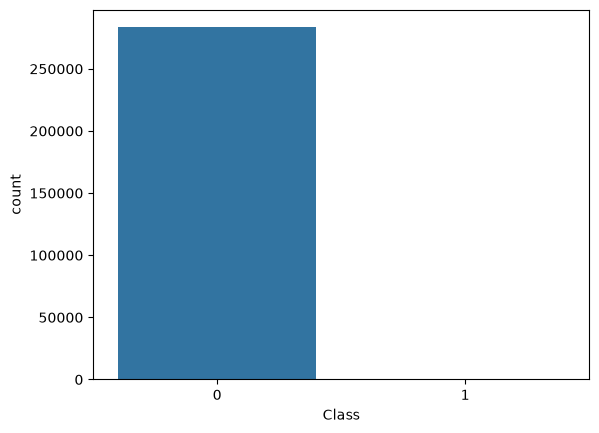

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=cc, x="Class")


<Axes: xlabel='Class', ylabel='Amount'>

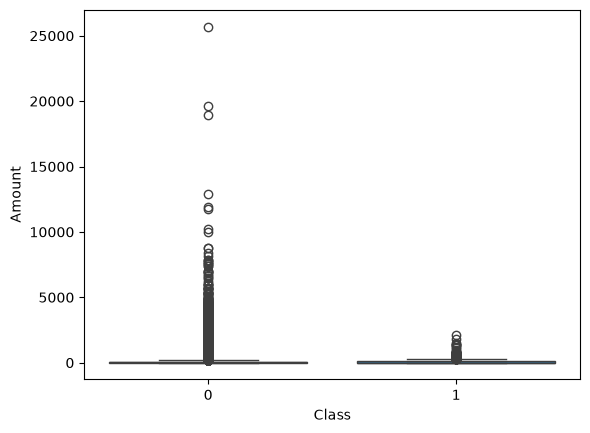

In [13]:
sns.boxplot(data=cc, x="Class", y="Amount")

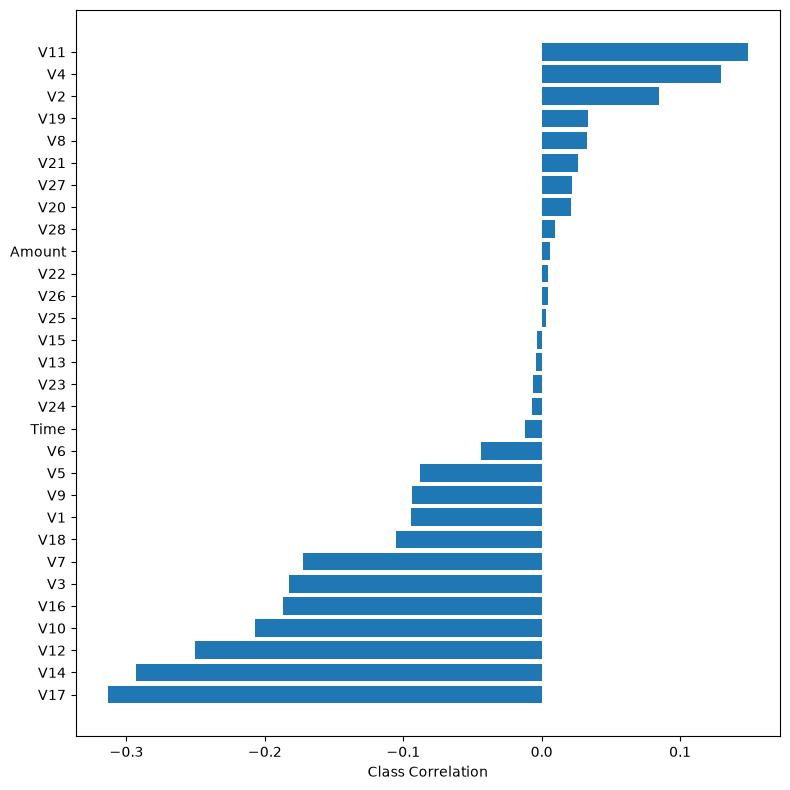

In [14]:
ordered = cc.corr(numeric_only=True)["Class"].drop("Class").sort_values()

plt.figure(figsize=(8, 8))
plt.barh(ordered.index, ordered.values)
plt.xlabel("Class Correlation")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

x = cc.drop(columns=["Class", "Time"])
y = cc["Class"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)

train = x_train.copy()
train["Class"] = y_train

fraud = train[train["Class"] == 1]
normal = train[train["Class"] == 0].sample(n=len(fraud), random_state=42)
train_bal = pd.concat([fraud, normal]).sample(frac=1, random_state=42)

x_train = train_bal.drop(columns="Class")
y_train = train_bal["Class"]

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split

def algo_test(x, y):
    modeller = [
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42)),
        make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42, n_jobs=-1)),
        make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42)),
        make_pipeline(StandardScaler(), KNeighborsClassifier()),
        make_pipeline(StandardScaler(), AdaBoostClassifier(random_state=42)),
    ]
    isimler = [
        "LogisticRegression",
        "DecisionTreeClassifier",
        "RandomForestClassifier",
        "GradientBoostingClassifier",
        "KNeighborsClassifier",
        "AdaBoostClassifier",
    ]

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42, stratify=y
    )

    train = x_train.copy()
    train["Class"] = y_train.to_numpy()
    fraud = train[train["Class"] == 1]
    normal = train[train["Class"] == 0].sample(n=len(fraud), random_state=42)
    train_bal = pd.concat([fraud, normal]).sample(frac=1, random_state=42)

    x_train = train_bal.drop(columns="Class")
    y_train = train_bal["Class"]

    accuracy, precision, recall, f1, mdl = [], [], [], [], []

    for model in modeller:
        model.fit(x_train, y_train)
        tahmin = model.predict(x_test)
        mdl.append(model)
        accuracy.append(accuracy_score(y_test, tahmin))
        precision.append(precision_score(y_test, tahmin, pos_label=1, zero_division=0))
        recall.append(recall_score(y_test, tahmin, pos_label=1, zero_division=0))
        f1.append(f1_score(y_test, tahmin, pos_label=1, zero_division=0))

    metrics = pd.DataFrame(
        {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1, "Model": mdl},
        index=isimler,
    )
    metrics.sort_values("F1", ascending=False, inplace=True)
    return metrics, x_test, y_test

metrics, x_test, y_test = algo_test(x, y)
metrics.drop("Model", axis=1)

,Accuracy,Precision,Recall,F1
RandomForestClassifier,0.985514,0.092945,0.873684,0.168016
LogisticRegression,0.978712,0.064894,0.873684,0.120815
KNeighborsClassifier,0.972527,0.047590,0.810526,0.089901
GradientBoostingClassifier,0.968773,0.044541,0.863158,0.084711
AdaBoostClassifier,0.963469,0.038282,0.863158,0.073312
DecisionTreeClassifier,0.920893,0.019046,0.915789,0.037315


Best model: RandomForestClassifier
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.09      0.87      0.17        95

    accuracy                           0.99     56746
   macro avg       0.55      0.93      0.58     56746
weighted avg       1.00      0.99      0.99     56746



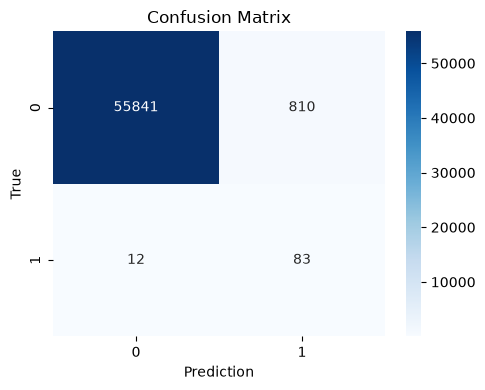

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

best = metrics.iloc[0]["Model"]
pred = best.predict(x_test)

print("Best model:", metrics.index[0])
print(classification_report(y_test, pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()



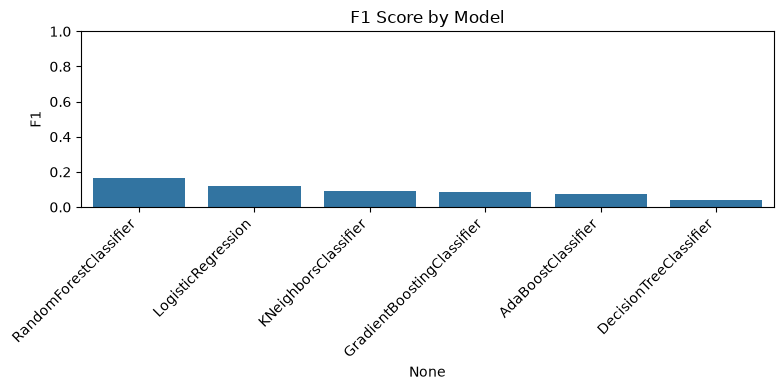

In [18]:
plt.figure(figsize=(8, 4))
sns.barplot(x=metrics.index, y=metrics["F1"])
plt.title("F1 Score by Model")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Accuracy : 0.9715045994431326
Precision: 0.04970414201183432
Recall   : 0.8842105263157894
F1       : 0.09411764705882353
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.88      0.09        95

    accuracy                           0.97     56746
   macro avg       0.52      0.93      0.54     56746
weighted avg       1.00      0.97      0.98     56746



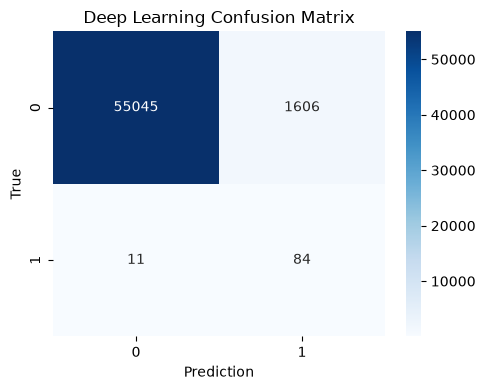

In [19]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

train = x_train.copy()
train["Class"] = y_train.to_numpy()
fraud = train[train["Class"] == 1]
normal = train[train["Class"] == 0].sample(n=len(fraud), random_state=42)
train_bal = pd.concat([fraud, normal]).sample(frac=1, random_state=42)
x_train = train_bal.drop(columns="Class")
y_train = train_bal["Class"]

x_scaler = StandardScaler()
x_tr = x_scaler.fit_transform(x_train)
x_te = x_scaler.transform(x_test)
y_tr = y_train.to_numpy()

dl = keras.Sequential([
    keras.layers.Input(shape=(x_tr.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
dl.compile(optimizer="adam", loss="binary_crossentropy")
dl.fit(
    x_tr, y_tr,
    validation_split=0.2,
    epochs=80,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=0,
)

pred = (dl.predict(x_te, verbose=0).ravel() >= 0.5).astype(int)
print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, pos_label=1, zero_division=0))
print("Recall   :", recall_score(y_test, pred, pos_label=1, zero_division=0))
print("F1       :", f1_score(y_test, pred, pos_label=1, zero_division=0))
print(classification_report(y_test, pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Deep Learning Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [20]:
import joblib

joblib.dump(best, "Classification1creditcard.joblib")

['Classification1creditcard.joblib']

# Conclusion

I checked the credit card data, dropped the duplicate rows and looked at the Class counts. The data is highly unbalanced, only a small part of the transactions are fraud. I compared the features with Class, dropped Time, balanced only the training set and scaled the columns. Then I tried Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, KNeighbors and AdaBoost. Random Forest gave the best F1 on the fraud class then saved the model as Classification1creditcard.joblib